# 题目2：苹果品质预测

使用决策树模型对苹果品质进行预测，t1是含糖量，t2是含水量，y标签表示苹果的好坏（1表示好，0表示不好）

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, auc

# 修改'gbk'错误
from sklearn import set_config
set_config(display='text') # 用纯文本显示

# 设置中文显示，防止图表中文乱码
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号


## 1、数据集的加载和清洗，分割训练集和测试集

In [13]:
df = pd.read_csv('数据/smt.txt', header=None, names=['t1', 't2', 'y'])
print("数据集形状：", df.shape)
print("\n数据基本信息：")
print(df.info())
print("\n缺失值统计：")
print(df.isnull().sum())
print("\n标签分布：")
print(df['y'].value_counts())

数据集形状： (17, 3)

数据基本信息：
<class 'pandas.DataFrame'>
RangeIndex: 17 entries, 0 to 16
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   t1      17 non-null     float64
 1   t2      17 non-null     float64
 2   y       17 non-null     int64  
dtypes: float64(2), int64(1)
memory usage: 540.0 bytes
None

缺失值统计：
t1    0
t2    0
y     0
dtype: int64

标签分布：
y
0    9
1    8
Name: count, dtype: int64


In [14]:
X = df[['t1', 't2']].values
y = df['y'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("训练集大小：", X_train.shape)
print("测试集大小：", X_test.shape)
print("训练集标签分布：", pd.Series(y_train).value_counts().to_dict())
print("测试集标签分布：", pd.Series(y_test).value_counts().to_dict())

训练集大小： (11, 2)
测试集大小： (6, 2)
训练集标签分布： {0: 6, 1: 5}
测试集标签分布： {1: 3, 0: 3}


## 2、调用sklearn的决策树算法

In [15]:
dt_clf = DecisionTreeClassifier(random_state=42)

## 3、使用决策树训练数据并预测测试集的准确率

In [16]:
dt_clf.fit(X_train, y_train)
y_pred_basic = dt_clf.predict(X_test)
accuracy_basic = accuracy_score(y_test, y_pred_basic)

print("调优前决策树测试集准确率：",accuracy_basic)
print("\n调优前决策树深度：", dt_clf.get_depth())
print("调优前决策树叶子节点数：", dt_clf.get_n_leaves())

调优前决策树测试集准确率： 0.6666666666666666

调优前决策树深度： 2
调优前决策树叶子节点数： 3


## 4、3折交叉验证和网格搜索，超参数调优

In [17]:
# 网格搜索
param_grid = {
    'criterion': ['gini', 'entropy'],  # 分裂准则
    'max_depth': [None, 2, 3, 4, 5], # 树的最大深度
    'min_samples_split': [2, 3, 4], # 节点再分裂的最小样本数
    'min_samples_leaf': [1, 2, 3] # 叶子节点的最小样本数
}

# 交叉验证
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [None, 2, 3, 4, 5],
                         'min_samples_leaf': [1, 2, 3],
                         'min_samples_split': [2, 3, 4]},
             scoring='accuracy')

## 5、最佳分数、最佳参数和最佳模型

In [18]:
print("最佳分数",grid_search.best_score_)
print("\n最佳参数：")
for k, v in grid_search.best_params_.items():
    print("  {} = {}".format(k, v))

best_dt = grid_search.best_estimator_
print("\n最佳模型：")
print(best_dt)

最佳分数 0.7222222222222222

最佳参数：
  criterion = gini
  max_depth = None
  min_samples_leaf = 1
  min_samples_split = 2

最佳模型：
DecisionTreeClassifier(random_state=42)


## 6、使用最佳模型预测测试集，三个不同指标评估

In [19]:
y_pred_best = best_dt.predict(X_test)

accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)

print("最佳模型测试集评估指标：")
print("  准确率 (Accuracy) :",accuracy_best)
print("  精确率 (Precision):",precision_best)
print("  召回率 (Recall)   :",recall_best)

最佳模型测试集评估指标：
  准确率 (Accuracy) : 0.6666666666666666
  精确率 (Precision): 0.6666666666666666
  召回率 (Recall)   : 0.6666666666666666


## 7、模型调优前后的准确率对比

  调优前准确率： 0.6666666666666666
  调优后准确率： 0.6666666666666666
  准确率变化： 0.0
  结果：调优前后准确率相同


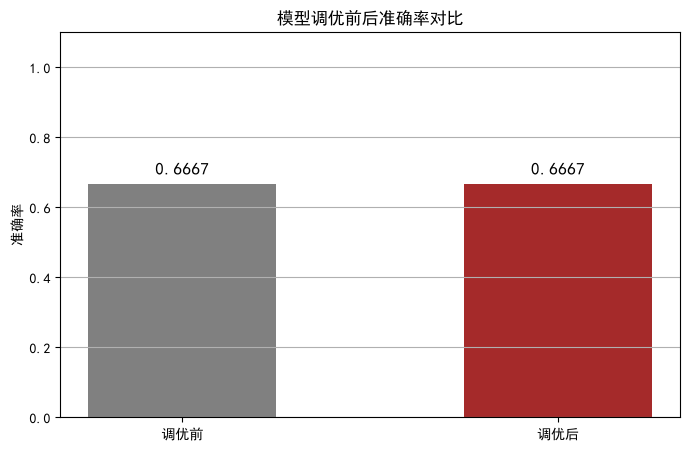

In [20]:
print("  调优前准确率：",accuracy_basic)
print("  调优后准确率：",accuracy_best)
print("  准确率变化：",accuracy_best - accuracy_basic)
if accuracy_best > accuracy_basic:
    print("  结果：调优后准确率提升")
elif accuracy_best < accuracy_basic:
    print("  结果：调优后准确率下降")
else:
    print("  结果：调优前后准确率相同")
print("=" * 50)

plt.figure(figsize=(8, 5))
models = ['调优前', '调优后']
accuracies = [accuracy_basic, accuracy_best]
bars = plt.bar(models, accuracies, color=['grey', 'brown'], width=0.5)
plt.ylim(0, 1.1)
plt.ylabel('准确率')
plt.title('模型调优前后准确率对比')
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             '{:.4f}'.format(acc), ha='center', va='bottom', fontsize=12)
plt.grid(axis='y')
plt.show()

## 8、绘制调优后模型的ROC曲线

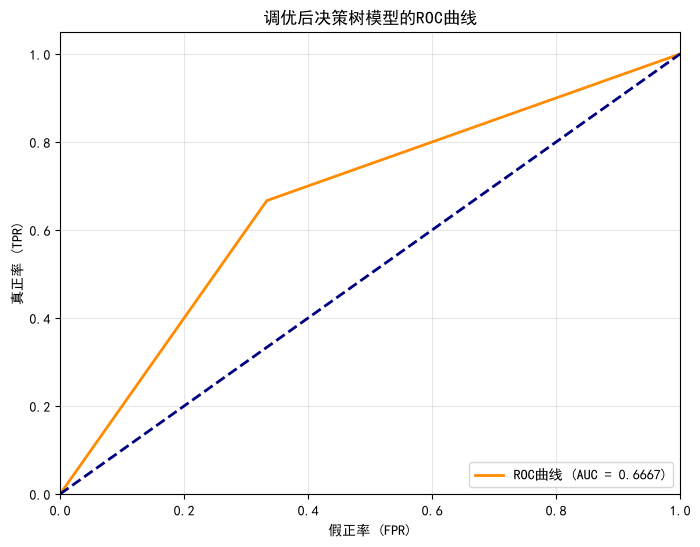

AUC值： 0.6666666666666667


In [21]:
# 获取模型预测概率
y_pred_proba = best_dt.predict_proba(X_test)[:, 1]

# FPR、TPR和AUC值
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label='ROC曲线 (AUC = {:.4f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('假正率 (FPR)')
plt.ylabel('真正率 (TPR)')
plt.title('调优后决策树模型的ROC曲线')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

print("AUC值：",roc_auc)